In [1]:
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from aeon.visualisation import create_multi_comparison_matrix

In [2]:
def get_value(s, key, default_value):
    if f"{key}=" in s:
        value = s.rstrip(")").split(f"{key}=")[1]
        if value[0] == "[":
            return value.split("]")[0] + "]"
        else:
            return value.split(",")[0]
    else:
        return default_value


def read_data(name: str, parameters: dict[str, Any]) -> pd.DataFrame:
    df_ = pd.read_csv(f"../results/sensitivity-analysis/effect-of-{name}.csv")
    for k, v in parameters.items():
        df_[k] = df_["Detector"].apply(lambda s: get_value(s, k, v))
    df_["seed"] = df_["Detector"].apply(lambda s: int(get_value(s, "seed", None)))
    df_.rename(columns={"VolumeUnderPR_TSBAD(threshold=75)": "VUS-PR"}, inplace=True)
    return df_

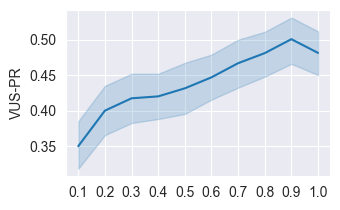

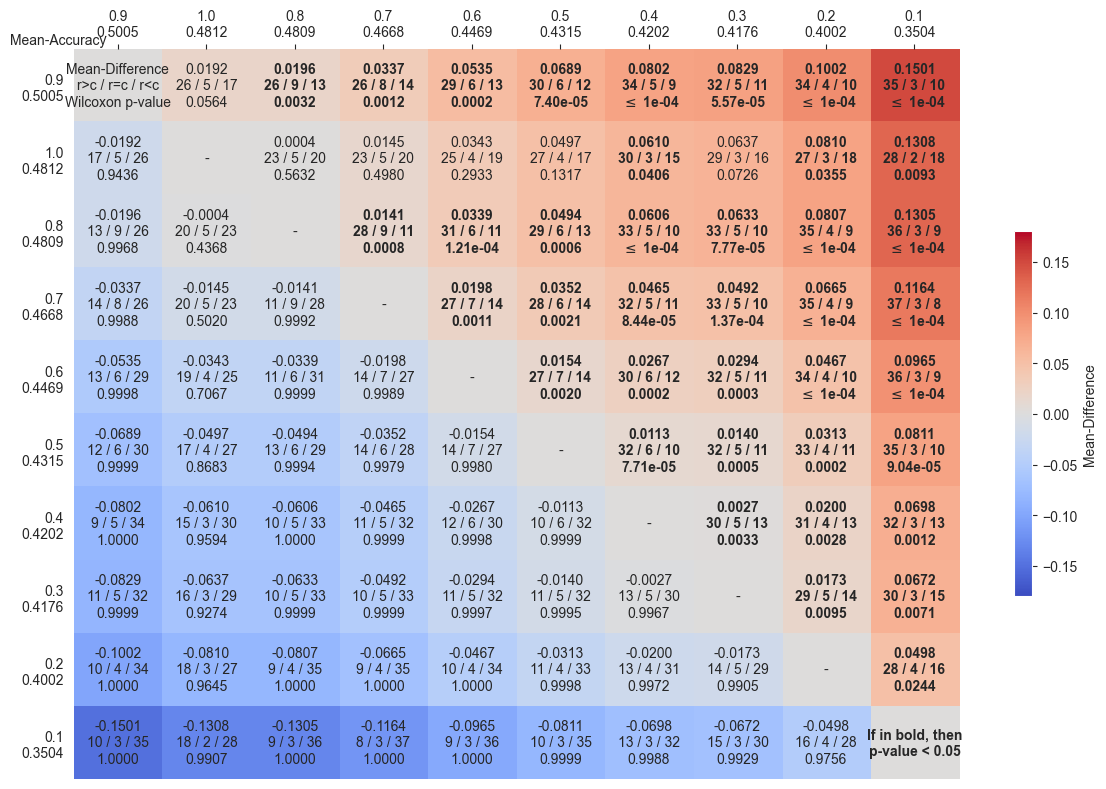

In [78]:
df = read_data("quantiles", {"quantile": 0.8})
df["quantile"] = df["quantile"].astype(float)

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))
sns.lineplot(df, x="quantile", y="VUS-PR", ax=ax)
ax.set_xticks(df["quantile"].unique())
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-quantile.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "quantile"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="quantile", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));

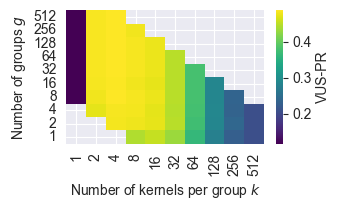

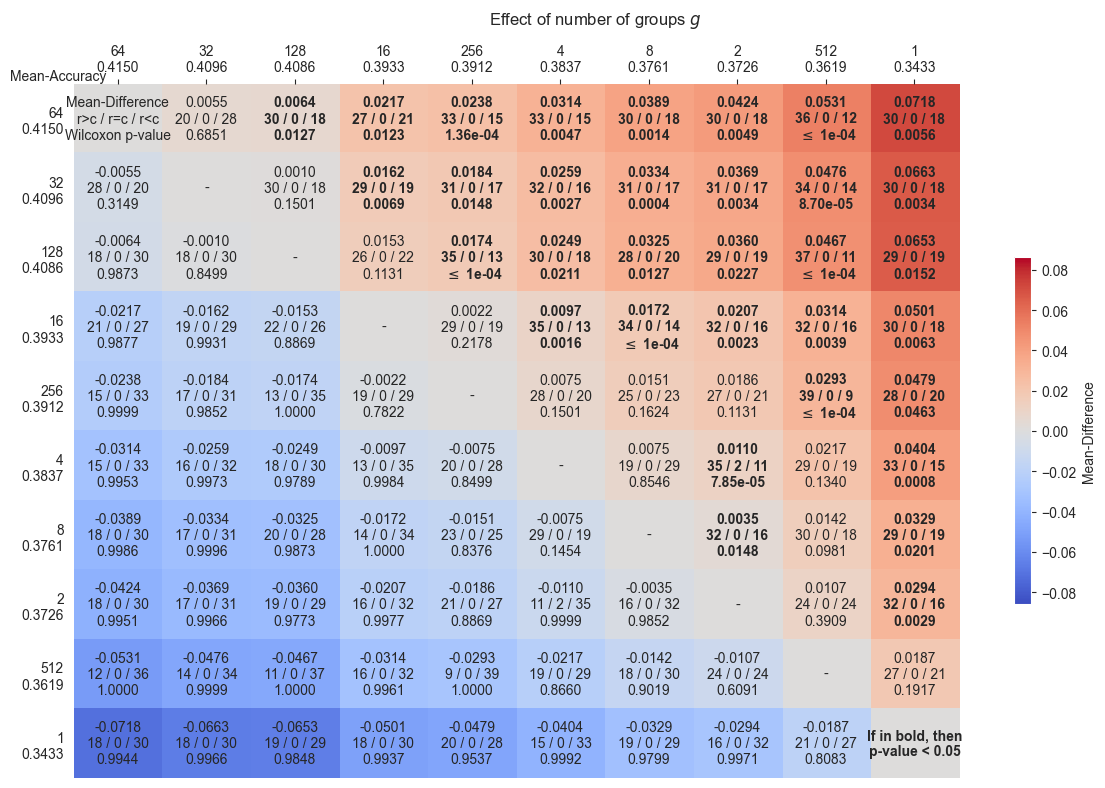

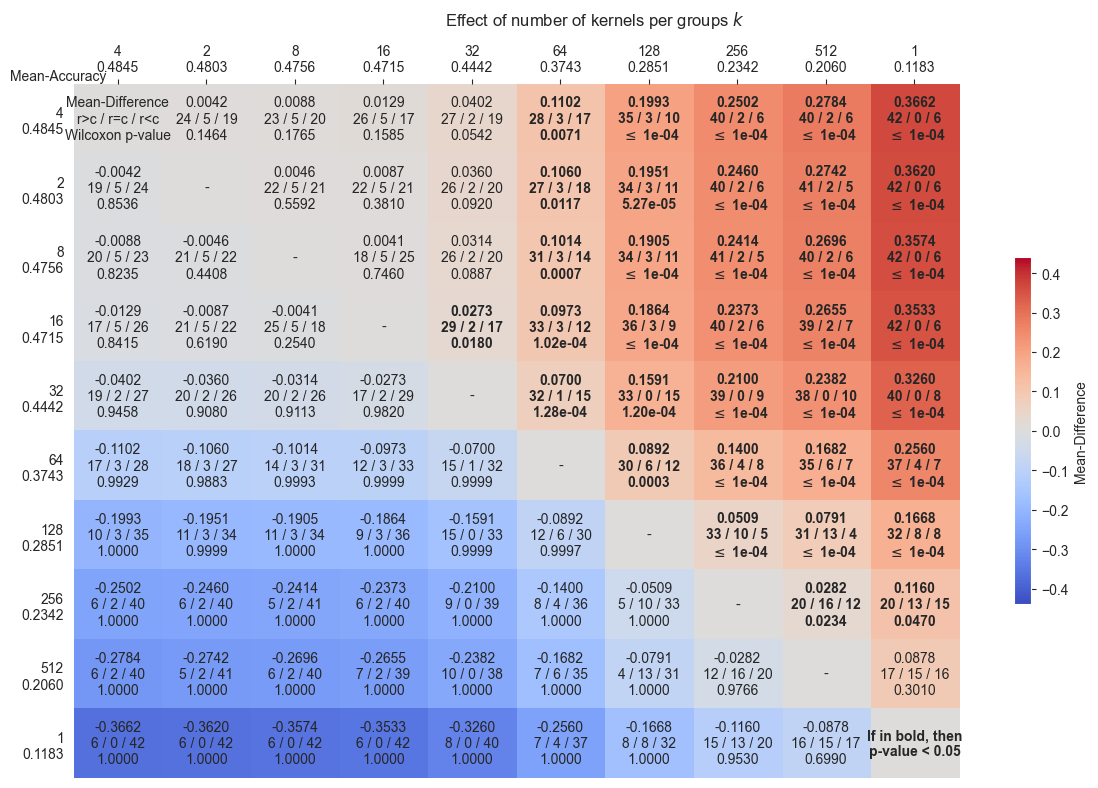

In [77]:
df = read_data("number-of-kernels", {"n_kernels": 8, "n_groups": 32})
df["n_kernels"] = df["n_kernels"].astype(int)
df["n_groups"] = df["n_groups"].astype(int)
fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))

pivot_table = df.pivot_table(values="VUS-PR", index="n_groups", columns="n_kernels")
sns.heatmap(pivot_table, annot=False, fmt=".2f", ax=ax, cmap="viridis")
ax.invert_yaxis()
ax.set_ylabel("Number of groups $g$")
ax.set_xlabel("Number of kernels per group $k$")
ax.collections[0].colorbar.set_label("VUS-PR", labelpad=3)

# Rotate the y-axis labels to horizontal
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
fig.savefig("figures/fig-sensitivity-k-and-g.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "n_groups"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="n_groups", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8)).suptitle(
    "Effect of number of groups $g$"
)

mean_scores = df.groupby(["Dataset", "n_kernels"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="n_kernels", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8)).suptitle(
    "Effect of number of kernels per groups $k$"
);

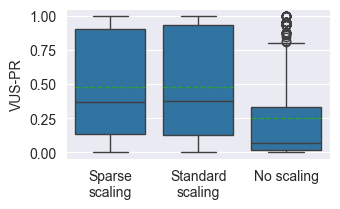

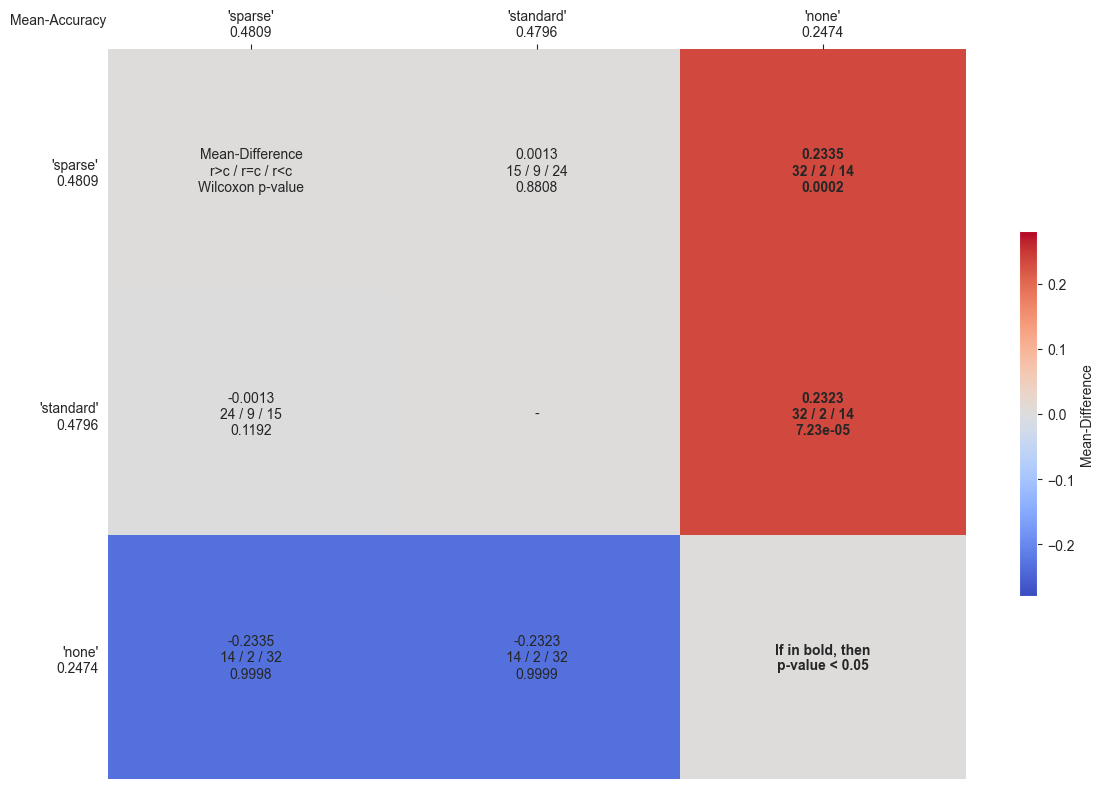

In [79]:
df = read_data("scaling", {"scaling": "'sparse'"})

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))
sns.boxplot(df, x="scaling", y="VUS-PR", ax=ax, meanline=True, showmeans=True)
ax.set_xticks(
    ["'sparse'", "'standard'", "'none'"],
    ["Sparse\nscaling", "Standard\nscaling", "No scaling"],
)
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-scaling.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "scaling"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="scaling", values="VUS-PR"
)

mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));

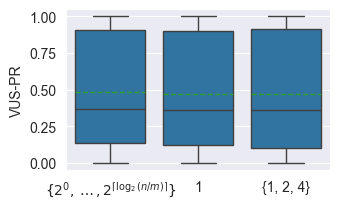

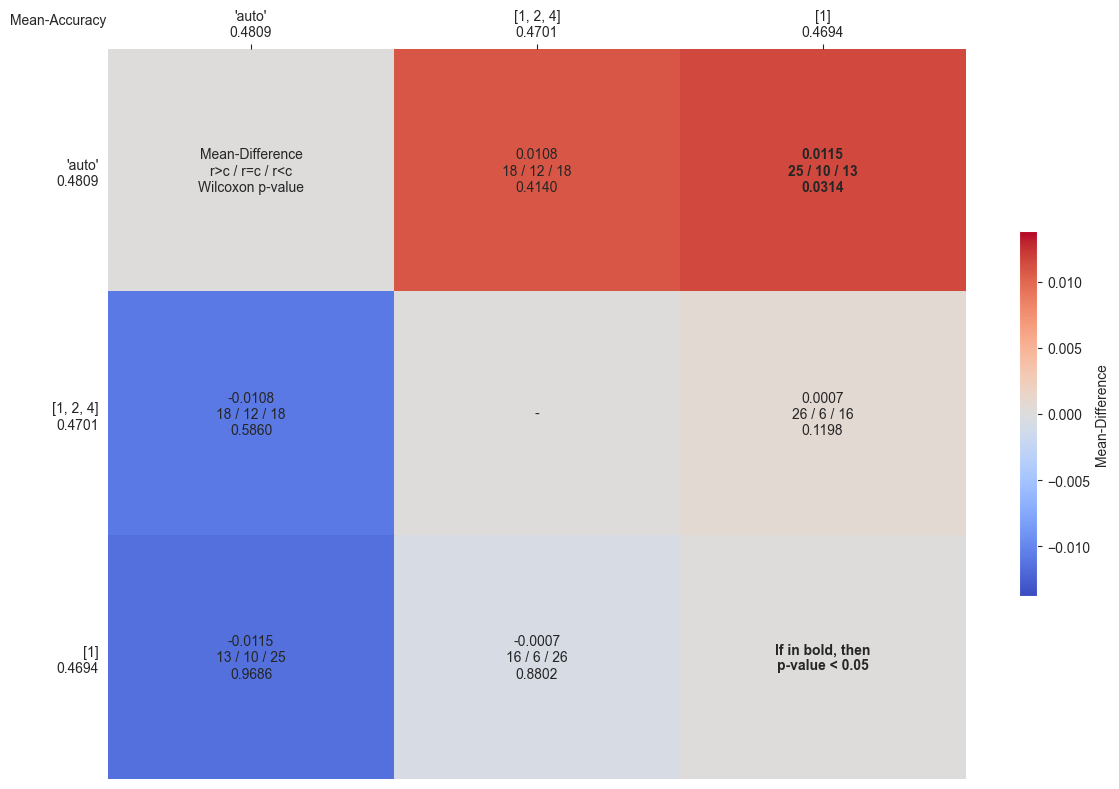

In [85]:
df = read_data("dilations", {"dilations": "'auto'"})

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))
sns.boxplot(df, x="dilations", y="VUS-PR", ax=ax, meanline=True, showmeans=True)
ax.set_xticks(
    ["'auto'", "[1]", "[1, 2, 4]"],
    [r"$\{2^0, \dots, 2^{\lceil \log_2(n / m)\rceil}\}$", "1", "{1, 2, 4}"],
)
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-dilations.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "dilations"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="dilations", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));

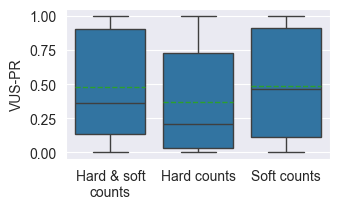

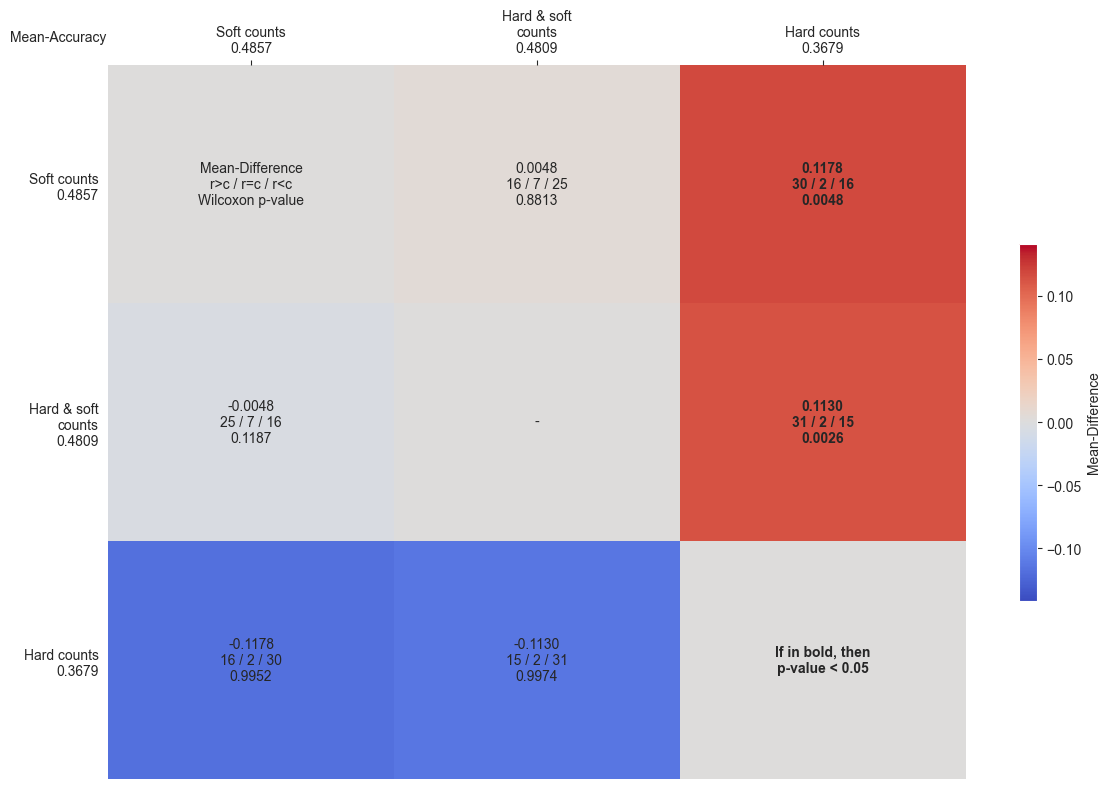

In [81]:
df = read_data("counts", {"hard_counts": "True", "soft_counts": "True"})
df["(hard_counts, soft_counts)"] = (
    df[["hard_counts", "soft_counts"]].apply(tuple, axis=1).astype(str)
)
df["(hard_counts, soft_counts)"] = df.apply(
    lambda row: (
        "Hard & soft\ncounts"
        if (row["hard_counts"] == "True" and row["soft_counts"] == "True")
        else "Hard counts"
        if row["hard_counts"] == "True"
        else "Soft counts"
    ),
    axis=1,
)

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))
sns.boxplot(
    df, x="(hard_counts, soft_counts)", y="VUS-PR", ax=ax, meanline=True, showmeans=True
)
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-counts.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "(hard_counts, soft_counts)"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="(hard_counts, soft_counts)", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));

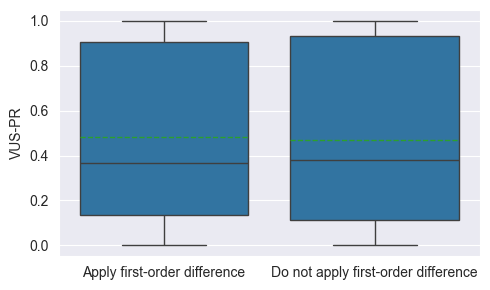

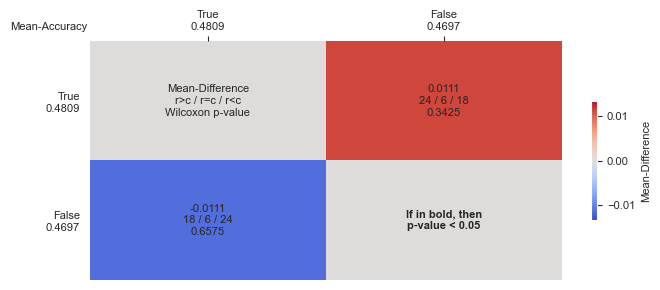

In [27]:
df = read_data("first-order-difference", {"first_order_difference": True})

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.boxplot(
    df, x="first_order_difference", y="VUS-PR", ax=ax, meanline=True, showmeans=True
)
ax.set_xticks(
    ["True", "False"],
    ["Apply first-order difference", "Do not apply first-order difference"],
)
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-first-order-difference.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "first_order_difference"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="first_order_difference", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores);

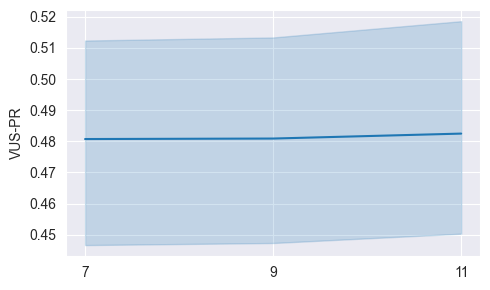

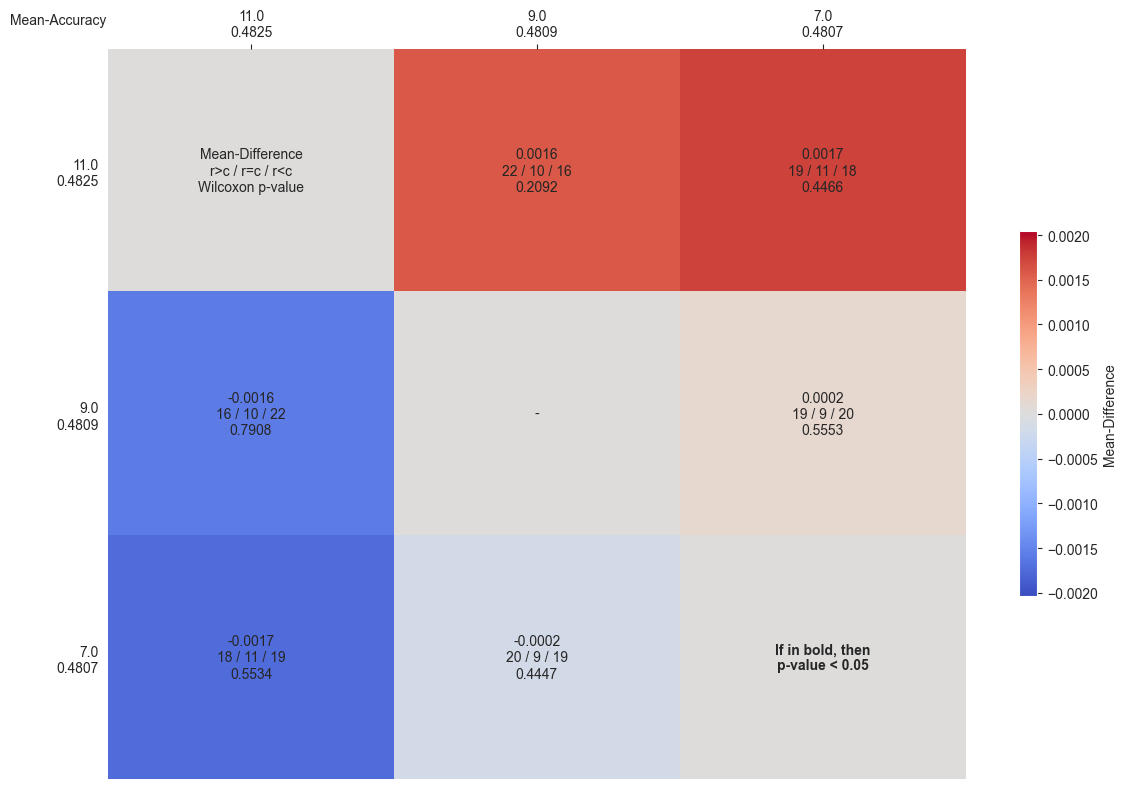

In [29]:
df = read_data("kernel-size", {"kernel_size": 9})
df["kernel_size"] = df["kernel_size"].astype(float)

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.lineplot(df, x="kernel_size", y="VUS-PR", ax=ax)
ax.set_xticks(df["kernel_size"].unique())
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-kernel-size.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "kernel_size"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="kernel_size", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));

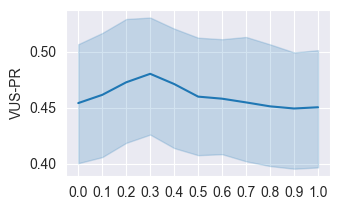

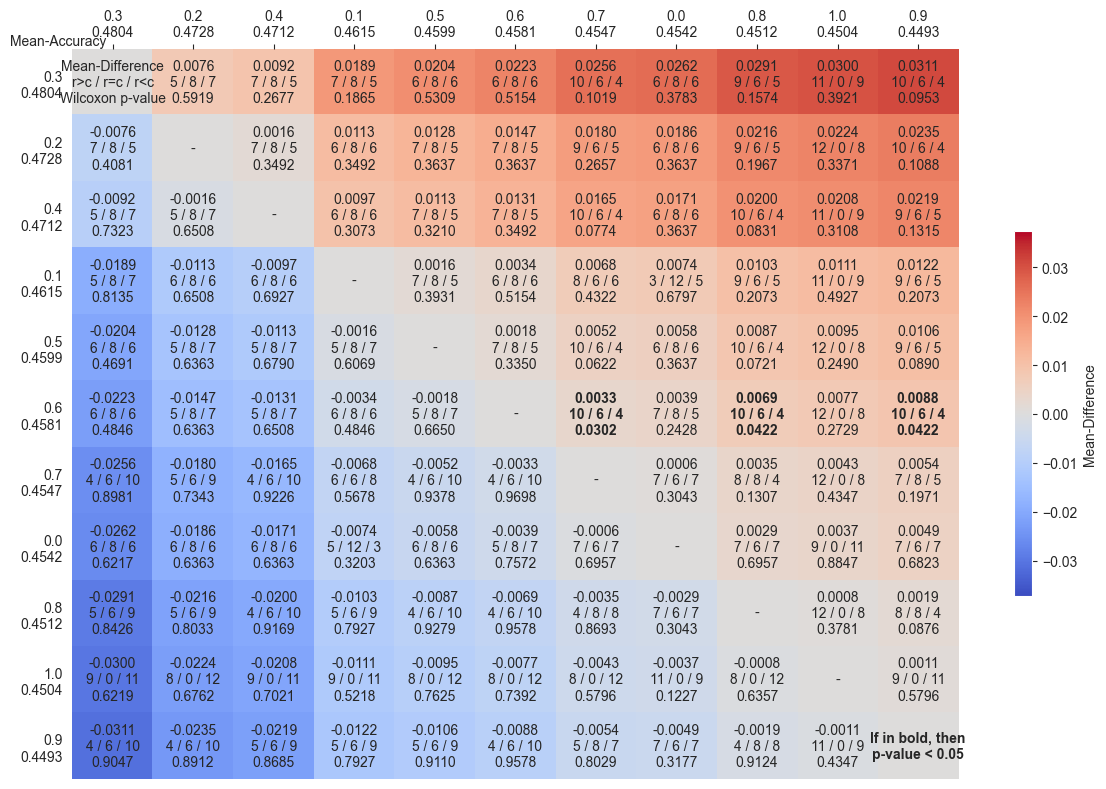

In [82]:
df = read_data("n-channels", {"n_channels": 0.5})
df["n_channels"] = df["n_channels"].astype(float)

fig, ax = plt.subplots(1, 1, figsize=(3.5, 2.2))
sns.lineplot(df, x="n_channels", y="VUS-PR", ax=ax)
ax.set_xticks(df["n_channels"].unique())
ax.set_xlabel("")
fig.savefig("figures/fig-sensitivity-n-channels.png", bbox_inches="tight")

mean_scores = df.groupby(["Dataset", "n_channels"])["VUS-PR"].mean()
mean_scores = mean_scores.reset_index().pivot(
    index="Dataset", columns="n_channels", values="VUS-PR"
)
mean_scores.columns = [str(col) for col in mean_scores.columns]
create_multi_comparison_matrix(mean_scores, fig_size=(12, 8));